In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt 
from models.models import FrequencyAdaptationLayer, CNN, classifier
from dataloader.dataloader import data_generator
from sklearn.metrics import f1_score, accuracy_score
# from models.loss import SinkhornDistance
# from pytorch_metric_learning import losses
# from algorithms.RAINCOAT import RAINCOAT
from models.models import classifier
import umap


In [12]:
class FD():
    def __init__(self):
        super(FD, self).__init__()
        self.sequence_len = 5120
        # self.scenarios = [("0", "1"), ("1", "2"), ("3", "1"), ("1", "0"), ("2", "3")]
        self.scenarios = [("0", "1"), ("0", "2"), ("0", "3"), ("1", "0"), ("1", "3"), ("2", "0"), ("2", "1"), ("3", "0"), ("3", "2")]
        self.class_names = ['Healthy', 'D1', 'D2']
        self.num_classes = 3
        self.shuffle = True
        self.drop_last = False
        self.normalize = True

        # Model configs
        self.input_channels = 1
        self.kernel_size = 32
        self.stride = 1
        self.dropout = 0.5

        self.mid_channels = 64
        self.final_out_channels = 128
        self.features_len = 1

        # TCN features
        self.tcn_layers = [75, 150]
        self.tcn_final_out_channles = self.tcn_layers[-1]
        self.tcn_kernel_size = 17
        self.tcn_dropout = 0.0

        # lstm features
        self.lstm_hid = 128
        self.lstm_n_layers = 1
        self.lstm_bid = False

        # discriminator
        self.disc_hid_dim = 64
        self.DSKN_disc_hid = 128
        self.hidden_dim = 500
        self.AR_hid_dim = 128
        self.fourier_modes = 64
        
        self.intra_only = True
        self.num_splits = 8

        self.AR_hid_dim_raw = self.input_channels


data_path = 'dataset/FD'
src_id = '2'
trg_id = '1'
dataset_configs = FD()
hparams = {"batch_size":64, 'learning_rate':1e-3,'weight_decay': 1e-4,'num_epochs': 100}

src_train_dl = data_generator(data_path, src_id, dataset_configs, hparams, "test")
trg_train_dl = data_generator(data_path, trg_id, dataset_configs, hparams, "test")

freq_adapter = FrequencyAdaptationLayer(
            seq_len=5120,
            channels=1,
            amp_scale=0.80482,
            phase_scale=1.69806,
            hidden_dim=64
        )
feature_extractor = CNN(FD())
Classifier = classifier(FD())
network = nn.Sequential(freq_adapter, feature_extractor, Classifier)
network.load_state_dict(torch.load(f'exp/FD/proposed/{src_id}_to_{trg_id}_run_0/checkpoint.pt')['best'])

<All keys matched successfully>

In [13]:
feat_original_list = []
feat_src_list = []
feat_adapted_list = []
labels_list = []
src_labels_list = []
network.to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
feature_extractor.eval()
freq_adapter.eval()
with torch.no_grad():
    for step, (trg_x, trg_y, _) in enumerate(trg_train_dl):
        trg_x = trg_x.float().to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
        orig_feat, _ = feature_extractor(trg_x)
        adapted_x = freq_adapter(trg_x)
        adapted_feat, _ = feature_extractor(adapted_x)
        feat_original_list.append(orig_feat.cpu().numpy())
        feat_adapted_list.append(adapted_feat.cpu().numpy())
        labels_list.append(trg_y.cpu().numpy())
        # diff = torch.norm(adapted_feat - orig_feat)
        # print(f"Feature Shift Magnitude: {diff.item()}")
        
    for step, (src_x, src_y, _) in enumerate(src_train_dl):
        src_x = src_x.float().to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
        src_feat, _ = feature_extractor(src_x)
        feat_src_list.append(src_feat.cpu().numpy())
        src_labels_list.append(src_y.cpu().numpy())
X_orig = np.concatenate(feat_original_list, axis=0)
X_adap = np.concatenate(feat_adapted_list, axis=0)
X_src = np.concatenate(feat_src_list, axis=0)
Y = np.concatenate(labels_list, axis=0)
Y_src = np.concatenate(src_labels_list, axis=0)

=== 定量评估指标 ===
Target 原始特征轮廓系数 (Silhouette Score): 0.4002
Target 适应后特征轮廓系数 (Silhouette Score): 0.4012
提升幅度: +0.0010

=== 定量指标：NMI (标准化互信息) ===
Target 原始特征 NMI 分数: 0.5761
Target 适应后特征 NMI 分数: 0.5731
NMI 提升幅度: -0.0030

=== 正在计算 UMAP 降维 (可能需要几十秒) ===


/root/miniconda3/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


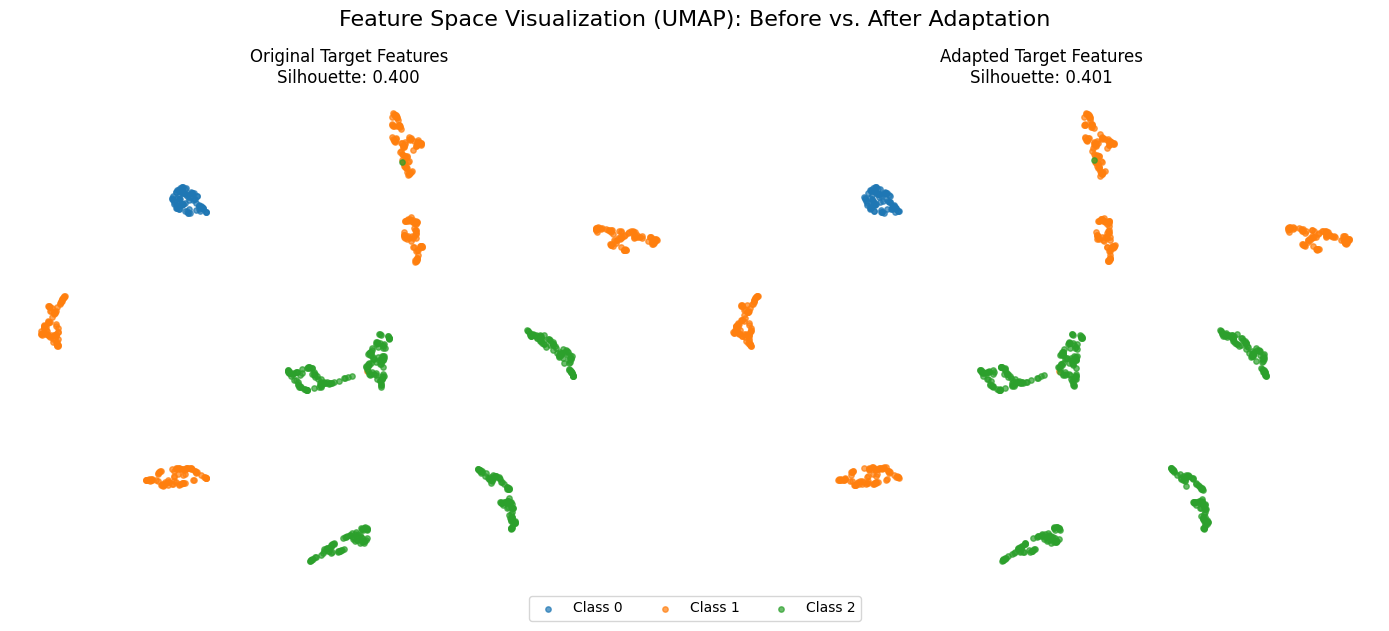

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.cluster import KMeans

# 假设你已经运行了你上面的代码，得到了 X_orig, X_adap, X_src, Y, Y_src
# X 形状应为 [N, Features] 且为 2D 数组。如果是 3D 的，记得用 X.reshape(X.shape[0], -1) 展平

# ==========================================
# 1. 定量分析：数值指标计算
# ==========================================
print("=== 定量评估指标 ===")

# 指标 A: Silhouette Score (在 Target 域上算，看类别是否分得更开)
sil_orig = silhouette_score(X_orig, Y)
sil_adap = silhouette_score(X_adap, Y)
print(f"Target 原始特征轮廓系数 (Silhouette Score): {sil_orig:.4f}")
print(f"Target 适应后特征轮廓系数 (Silhouette Score): {sil_adap:.4f}")
print(f"提升幅度: {sil_adap - sil_orig:+.4f}\n")

print("=== 定量指标：NMI (标准化互信息) ===")

# 1. 获取类别的真实数量 K
n_classes = len(np.unique(Y))

# 2. 对 Original Target Features 进行 K-Means 聚类
kmeans_orig = KMeans(n_clusters=n_classes, random_state=42, n_init=10)
cluster_labels_orig = kmeans_orig.fit_predict(X_orig) # 得到无监督聚类标签

# 3. 对 Adapted Target Features 进行 K-Means 聚类
kmeans_adap = KMeans(n_clusters=n_classes, random_state=42, n_init=10)
cluster_labels_adap = kmeans_adap.fit_predict(X_adap)

# 4. 计算 NMI
nmi_orig = normalized_mutual_info_score(Y, cluster_labels_orig)
nmi_adap = normalized_mutual_info_score(Y, cluster_labels_adap)

print(f"Target 原始特征 NMI 分数: {nmi_orig:.4f}")
print(f"Target 适应后特征 NMI 分数: {nmi_adap:.4f}")
print(f"NMI 提升幅度: {nmi_adap - nmi_orig:+.4f}\n")

# ==========================================
# 2. 定性分析：UMAP 降维可视化
# ==========================================
print("=== 正在计算 UMAP 降维 (可能需要几十秒) ===")
# 固定 random_state 以保证每次画图的结果一致
reducer = umap.UMAP(n_components=2, random_state=42)

# 将 original 和 adapted 拼在一起做降维，保证它们映射在同一个 2D 坐标系中方便对比
X_combined = np.concatenate([X_orig, X_adap], axis=0)
X_combined_2d = reducer.fit_transform(X_combined)

# 拆分回原来的两份
split_idx = X_orig.shape[0]
X_orig_2d = X_combined_2d[:split_idx]
X_adap_2d = X_combined_2d[split_idx:]

# 开始画图
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 获取类别的数量，用于分配颜色
classes = np.unique(Y)
cmap = plt.get_cmap('tab10') # 支持最多 10 个类别，类别更多请换 'tab20'

# 图1：Original Target Features
for cls in classes:
    idx = (Y == cls)
    axes[0].scatter(X_orig_2d[idx, 0], X_orig_2d[idx, 1], 
                    label=f'Class {cls}', alpha=0.7, s=15, c=[cmap(cls % 10)])
axes[0].set_title(f'Original Target Features\nSilhouette: {sil_orig:.3f}')
axes[0].axis('off') # 隐藏坐标轴，使得图看起来更干净

# 图2：Adapted Target Features
for cls in classes:
    idx = (Y == cls)
    axes[1].scatter(X_adap_2d[idx, 0], X_adap_2d[idx, 1], 
                    label=f'Class {cls}', alpha=0.7, s=15, c=[cmap(cls % 10)])
axes[1].set_title(f'Adapted Target Features\nSilhouette: {sil_adap:.3f}')
axes[1].axis('off')

# 添加图例
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(classes), bbox_to_anchor=(0.5, -0.05))

plt.suptitle("Feature Space Visualization (UMAP): Before vs. After Adaptation", fontsize=16)
plt.tight_layout()
plt.show()